In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)

from scipy.stats import loguniform

In [2]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/bank_marketing_20000_rows.csv")

In [3]:
df.head()

,customer_id,age,job,marital,education,account_balance,housing_loan,personal_loan,contact,last_contact_day,last_contact_month,call_duration_seconds,campaign_contacts,previous_contacts,previous_campaign_outcome,subscribed
0,BANK00001,54,blue-collar,married,secondary,-1817.82,yes,no,unknown,5,apr,170,14,5,other,0
1,BANK00002,59,services,divorced,secondary,7615.65,yes,no,cellular,8,jan,80,5,5,unknown,0
2,BANK00003,41,retired,married,secondary,9154.46,no,no,cellular,12,mar,167,10,7,failure,0
3,BANK00004,56,retired,single,primary,8599.85,no,no,unknown,16,jan,393,2,6,unknown,0
4,BANK00005,55,retired,single,secondary,-512.09,yes,no,cellular,29,apr,125,7,6,failure,0


In [4]:
df.tail()

,customer_id,age,job,marital,education,account_balance,housing_loan,personal_loan,contact,last_contact_day,last_contact_month,call_duration_seconds,campaign_contacts,previous_contacts,previous_campaign_outcome,subscribed
19995,BANK19996,65,admin,divorced,secondary,-212.68,yes,no,cellular,10,nov,221,14,3,unknown,0
19996,BANK19997,44,blue-collar,married,secondary,-2023.13,yes,no,unknown,13,dec,293,11,3,success,0
19997,BANK19998,18,retired,married,secondary,-3000.00,yes,yes,cellular,17,jan,88,10,1,unknown,0
19998,BANK19999,20,management,single,secondary,-3000.00,no,no,cellular,10,jun,170,3,6,other,0
19999,BANK20000,35,blue-collar,married,tertiary,7090.85,yes,no,cellular,25,jul,201,6,6,unknown,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                20000 non-null  object 
 1   age                        20000 non-null  int64  
 2   job                        20000 non-null  object 
 3   marital                    20000 non-null  object 
 4   education                  19800 non-null  object 
 5   account_balance            19760 non-null  float64
 6   housing_loan               20000 non-null  object 
 7   personal_loan              20000 non-null  object 
 8   contact                    19800 non-null  object 
 9   last_contact_day           20000 non-null  int64  
 10  last_contact_month         20000 non-null  object 
 11  call_duration_seconds      20000 non-null  int64  
 12  campaign_contacts          20000 non-null  int64  
 13  previous_contacts          20000 non-null  int

In [6]:
df.describe()

,age,account_balance,last_contact_day,call_duration_seconds,campaign_contacts,previous_contacts,subscribed
count,20000.000000,19760.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,44.052900,1471.481588,15.970850,239.657850,8.051900,3.501050,0.200350
std,15.328681,2518.613952,8.948916,159.464059,4.316091,2.294376,0.400272
min,18.000000,-3000.000000,1.000000,5.000000,1.000000,0.000000,0.000000
25%,31.000000,-355.797500,8.000000,122.000000,4.000000,1.000000,0.000000
50%,44.000000,1439.860000,16.000000,205.500000,8.000000,4.000000,0.000000
75%,57.000000,3169.440000,24.000000,320.250000,12.000000,6.000000,0.000000
max,70.000000,11933.200000,31.000000,1293.000000,15.000000,7.000000,1.000000


In [7]:
df.columns

Index(['customer_id', 'age', 'job', 'marital', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact', 'last_contact_day',
       'last_contact_month', 'call_duration_seconds', 'campaign_contacts',
       'previous_contacts', 'previous_campaign_outcome', 'subscribed'],
      dtype='object')

In [8]:
df.size

320000

In [9]:
df.isnull().sum()

customer_id                    0
age                            0
job                            0
marital                        0
education                    200
account_balance              240
housing_loan                   0
personal_loan                  0
contact                      200
last_contact_day               0
last_contact_month             0
call_duration_seconds          0
campaign_contacts              0
previous_contacts              0
previous_campaign_outcome    200
subscribed                     0
dtype: int64

In [10]:
df["education"]=df["education"].fillna(df["education"].mode()[0])
df["account_balance"]=df["account_balance"].fillna(df["account_balance"].mean())
df["contact"]=df["contact"].fillna(df["contact"].mode()[0])
df["previous_campaign_outcome"]=df["previous_campaign_outcome"].fillna(df["previous_campaign_outcome"].mode()[0])

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                20000 non-null  object 
 1   age                        20000 non-null  int64  
 2   job                        20000 non-null  object 
 3   marital                    20000 non-null  object 
 4   education                  20000 non-null  object 
 5   account_balance            20000 non-null  float64
 6   housing_loan               20000 non-null  object 
 7   personal_loan              20000 non-null  object 
 8   contact                    20000 non-null  object 
 9   last_contact_day           20000 non-null  int64  
 10  last_contact_month         20000 non-null  object 
 11  call_duration_seconds      20000 non-null  int64  
 12  campaign_contacts          20000 non-null  int64  
 13  previous_contacts          20000 non-null  int

In [12]:
df.isnull().sum()

customer_id                  0
age                          0
job                          0
marital                      0
education                    0
account_balance              0
housing_loan                 0
personal_loan                0
contact                      0
last_contact_day             0
last_contact_month           0
call_duration_seconds        0
campaign_contacts            0
previous_contacts            0
previous_campaign_outcome    0
subscribed                   0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
print(df.columns.tolist())

['customer_id', 'age', 'job', 'marital', 'education', 'account_balance', 'housing_loan', 'personal_loan', 'contact', 'last_contact_day', 'last_contact_month', 'call_duration_seconds', 'campaign_contacts', 'previous_contacts', 'previous_campaign_outcome', 'subscribed']


In [15]:
print(df.head())
print(df.shape)
print(df.info())

  customer_id  age          job   marital  education  account_balance  \
0   BANK00001   54  blue-collar   married  secondary         -1817.82   
1   BANK00002   59     services  divorced  secondary          7615.65   
2   BANK00003   41      retired   married  secondary          9154.46   
3   BANK00004   56      retired    single    primary          8599.85   
4   BANK00005   55      retired    single  secondary          -512.09   

  housing_loan personal_loan   contact  last_contact_day last_contact_month  \
0          yes            no   unknown                 5                apr   
1          yes            no  cellular                 8                jan   
2           no            no  cellular                12                mar   
3           no            no   unknown                16                jan   
4          yes            no  cellular                29                apr   

   call_duration_seconds  campaign_contacts  previous_contacts  \
0                   

In [16]:
df.columns = df.columns.str.strip()

In [17]:
print("Available columns:", df.columns.tolist())

Available columns: ['customer_id', 'age', 'job', 'marital', 'education', 'account_balance', 'housing_loan', 'personal_loan', 'contact', 'last_contact_day', 'last_contact_month', 'call_duration_seconds', 'campaign_contacts', 'previous_contacts', 'previous_campaign_outcome', 'subscribed']


In [18]:
# Feature Selection
X = df.drop(
    columns=["customer_id", "subscribed"]
)

y = df["subscribed"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [20]:
print(X_train.shape)

print(X_test.shape)

print(y_train.shape)

print(y_test.shape)

(16000, 14)
(4000, 14)
(16000,)
(4000,)


In [21]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("Categorical Features:")
print(categorical_features)

Numerical Features:
['age', 'account_balance', 'last_contact_day', 'call_duration_seconds', 'campaign_contacts', 'previous_contacts']
Categorical Features:
['job', 'marital', 'education', 'housing_loan', 'personal_loan', 'contact', 'last_contact_month', 'previous_campaign_outcome']


# Missing Values Handling

In [22]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [23]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Column Transformer

In [24]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Build SVM Model

In [25]:
model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

# Model Training

In [26]:
model.fit(X_train, y_train)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['age','job','marital',...,'campaign_contacts','previous_contacts', 'previous_campaign_outcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

# Prediction

In [27]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Model Evaluation

In [28]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

Accuracy: 0.676
Precision: 0.3173431734317343
Recall: 0.5368289637952559
F1 Score: 0.39888682745825604
ROC-AUC: 0.6607325791182405


In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.71      0.78      3199
           1       0.32      0.54      0.40       801

    accuracy                           0.68      4000
   macro avg       0.59      0.62      0.59      4000
weighted avg       0.75      0.68      0.70      4000



# Confusion Matrix

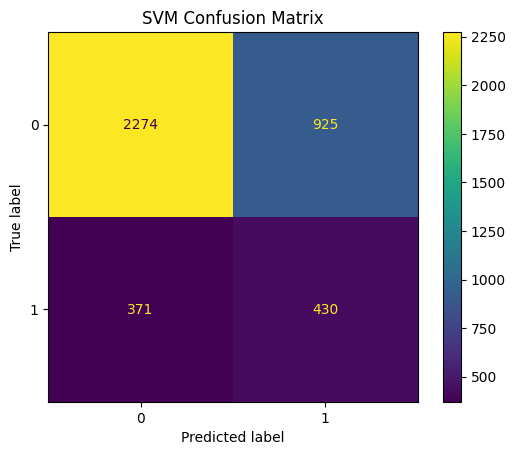

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("SVM Confusion Matrix")

plt.show()

# Hyperparameter Tuning

In [31]:
param_grid = {
    "classifier__C": loguniform(0.01, 100),

    "classifier__gamma": [
        "scale",
        "auto",
        0.001,
        0.01,
        0.1
    ],

    "classifier__kernel": [
        "rbf",
        "linear"
    ]
}

In [39]:
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=5,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [40]:
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.1

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': <scipy.stats....t 0x116e2dd30>, 'classifier__gamma': ['scale', 'auto', ...], 'classifier__kernel': ['rbf', 'linear']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichretur

In [41]:

print("Best Parameters:")
print(random_search.best_params_)

print("Best Score:")
print(random_search.best_score_)

Best Parameters:
{'classifier__C': np.float64(0.037279259033769864), 'classifier__gamma': 0.001, 'classifier__kernel': 'linear'}
Best Score:
0.42441472277984765


# Best Model

In [42]:
best_model = random_search.best_estimator_

tuned_pred = best_model.predict(X_test)

tuned_prob = best_model.predict_proba(X_test)[:, 1]

In [43]:
print("Accuracy:",
      accuracy_score(y_test, tuned_pred))
print("Precision:",
      precision_score(y_test, tuned_pred, zero_division=0))
print("Recall:",
      recall_score(y_test, tuned_pred, zero_division=0))
print("F1 Score:",
      f1_score(y_test, tuned_pred, zero_division=0))
print("ROC-AUC:",
      roc_auc_score(y_test, tuned_prob))

Accuracy: 0.6825
Precision: 0.3287070854638422
Recall: 0.5617977528089888
F1 Score: 0.4147465437788018
ROC-AUC: 0.6804108181434663


# Model Comparison

In [44]:
comparison = pd.DataFrame({

    "Model": ["Baseline SVM", "Tuned SVM"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, tuned_pred)
    ],

    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, tuned_pred, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, tuned_pred, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, tuned_pred, zero_division=0)
    ]

})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline SVM,0.6760,0.317343,0.536829,0.398887
1,Tuned SVM,0.6825,0.328707,0.561798,0.414747


# Save Model

In [38]:
joblib.dump(
    best_model,
    "bank_marketing_svm_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!
